## Eda 데이터 탐색

## 데이터 로드

- `ann_df`: bbox 한 개당 한 행 (이미지 메타 + 약 정보 + bbox)
- `img_df`: train 이미지 한 장당 한 행 (촬영 정보 + 객체 수)
- `cat_df`: category_id ↔ 약 이름
- `test_files`: test 이미지 파일명 목록

In [1]:
import json
from pathlib import Path

import pandas as pd

DATA_DIR = Path("../data")
# 압축을 푼 위치에 따라 sprint_ai_project1_data 폴더가 한 단계 더 있을 수 있다
if (DATA_DIR / "sprint_ai_project1_data").exists():
    DATA_DIR = DATA_DIR / "sprint_ai_project1_data"

TRAIN_IMG_DIR = DATA_DIR / "train_images"
TEST_IMG_DIR = DATA_DIR / "test_images"
ANN_DIR = DATA_DIR / "train_annotations"

IMG_EXTS = {".png", ".jpg", ".jpeg"}
# 이미지 단위로 같은 값을 갖는 촬영 정보. 나머지 필드(drug_N, dl_name 등)는 알약마다 다르다
IMAGE_COLS = ["file_name", "width", "height", "back_color", "light_color", "camera_la", "camera_lo", "size"]


def list_images(folder: Path) -> list[Path]:
    """Zone.Identifier 등을 빼고 이미지 파일만 반환한다."""
    return sorted(p for p in folder.iterdir() if p.suffix.lower() in IMG_EXTS)


def load_annotations(ann_dir: Path) -> pd.DataFrame:
    """json 하나 = 이미지 한 장 속 알약 한 종류. 모든 json을 bbox 한 개당 한 행으로 펼친다."""
    rows = []
    for path in sorted(ann_dir.rglob("*.json")):
        with open(path, encoding="utf-8") as f:
            data = json.load(f)
        images = {img["id"]: img for img in data["images"]}
        for ann in data["annotations"]:
            x, y, w, h = ann["bbox"]
            rows.append({
                **images[ann["image_id"]],
                "category_id": ann["category_id"],
                "x": x, "y": y, "w": w, "h": h,
                "area": ann["area"],
                "json_path": str(path),
            })
    return pd.DataFrame(rows).drop(columns=["id"])


ann_df = load_annotations(ANN_DIR)

# 이미지 단위 테이블: 어노테이션이 없는 이미지도 포함
img_df = pd.DataFrame({"file_name": [p.name for p in list_images(TRAIN_IMG_DIR)]})
img_meta = ann_df[IMAGE_COLS].drop_duplicates("file_name")
img_df = img_df.merge(img_meta, on="file_name", how="left")
img_df["n_objects"] = img_df["file_name"].map(ann_df["file_name"].value_counts()).fillna(0).astype(int)

# 클래스 테이블: category_id ↔ 약 이름
cat_df = (
    ann_df[["category_id", "dl_name", "dl_name_en"]]
    .drop_duplicates("category_id")
    .sort_values("category_id")
    .reset_index(drop=True)
)

test_files = [p.name for p in list_images(TEST_IMG_DIR)]

print("train 이미지:", len(img_df), "/ test 이미지:", len(test_files))
print("bbox 수:", len(ann_df), "/ 클래스 수:", len(cat_df))
print("어노테이션 없는 train 이미지:", (img_df["n_objects"] == 0).sum())
ann_df.head()

train 이미지: 232 / test 이미지: 842
bbox 수: 763 / 클래스 수: 56
어노테이션 없는 train 이미지: 0


,file_name,width,height,imgfile,drug_N,drug_S,back_color,drug_dir,light_color,camera_la,...,mark_code_front,mark_code_back,change_date,category_id,x,y,w,h,area,json_path
0,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,976,1280,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,K-001900,정상알약,연회색 배경,앞면,주백색,70,...,,,20160825,1900,644,845,189,190,35910,../data/train_annotations/K-001900-016548-0196...
1,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,976,1280,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,K-001900,정상알약,연회색 배경,앞면,주백색,75,...,,,20160825,1900,148,241,181,181,32761,../data/train_annotations/K-001900-016548-0196...
2,K-001900-016548-019607-029451_0_2_0_2_90_000_2...,976,1280,K-001900-016548-019607-029451_0_2_0_2_90_000_2...,K-001900,정상알약,연회색 배경,앞면,주백색,90,...,,,20160825,1900,167,248,184,182,33488,../data/train_annotations/K-001900-016548-0196...
3,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,976,1280,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,K-016548,정상알약,연회색 배경,앞면,주백색,70,...,NaN,NaN,NaN,16548,144,799,239,239,57121,../data/train_annotations/K-001900-016548-0196...
4,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,976,1280,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,K-016548,정상알약,연회색 배경,앞면,주백색,75,...,NaN,NaN,NaN,16548,578,222,233,226,52658,../data/train_annotations/K-001900-016548-0196...


## 데이터 정의서

`ann_df` 기준, bbox(알약) 1개당 1행입니다. 전체 763행, 56개 컬럼입니다.

### 이미지 정보

| 컬럼명 | 데이터 타입 | 설명 |
|---|---|---|
| file_name | str | 이미지 파일명. 이미지 단위의 키로 사용됩니다. 앞부분(`K-003351-018357-036637`)에 사진에 찍힌 약 코드가 들어 있습니다. |
| imgfile | str | 이미지 파일명. `file_name`과 같은 값입니다. |
| width | int | 이미지 너비(px). 전부 976입니다. |
| height | int | 이미지 높이(px). 전부 1280입니다. |
| json_path | str | 이 행을 읽어 온 어노테이션 json 파일 경로입니다. |

### 촬영 조건

| 컬럼명 | 데이터 타입 | 설명 |
|---|---|---|
| back_color | str | 배경색. 전부 `연회색 배경`입니다. |
| light_color | str | 조명 색. 전부 `주백색`입니다. |
| camera_la | int | 카메라 촬영 각도(위도). 70, 75, 90 세 가지입니다. |
| camera_lo | int | 카메라 회전 각도(경도). 전부 0입니다. |
| size | int | 촬영 크기 설정값. 전부 200입니다. |
| drug_dir | str | 촬영된 알약 면. `앞면` 또는 `뒷면`입니다. |
| drug_S | str | 알약 상태. 전부 `정상알약`입니다. |

### 정답 (타깃)

| 컬럼명 | 데이터 타입 | 설명 |
|---|---|---|
| category_id | int | **타깃 변수(클래스)**. 약 종류 코드이며 56종입니다. `drug_N`의 숫자 부분과 같습니다. |
| x | int | **타깃 변수(bbox)**. 박스 왼쪽 위 꼭짓점의 x 좌표(px)입니다. |
| y | int | **타깃 변수(bbox)**. 박스 왼쪽 위 꼭짓점의 y 좌표(px)입니다. |
| w | int | **타깃 변수(bbox)**. 박스 너비(px)입니다. |
| h | int | **타깃 변수(bbox)**. 박스 높이(px)입니다. |
| area | int | 박스 넓이(px²). `w × h`와 같습니다. |

### 약 식별 코드

| 컬럼명 | 데이터 타입 | 설명 |
|---|---|---|
| drug_N | str | 약 코드(예: `K-003351`). `category_id`에 `K-`를 붙인 형태입니다. |
| dl_mapping_code | str | 약 매핑 코드. `drug_N`과 같은 값입니다. |
| dl_idx | str | 약 코드의 숫자 부분(예: `3351`)입니다. (이 부분은 일단 눈여겨 보자)|
| item_seq | int | 식약처 품목기준코드입니다. |
| di_edi_code | str | 건강보험 EDI 코드. 여러 개면 쉼표로 구분합니다. |

### 약 기본 정보

| 컬럼명 | 데이터 타입 | 설명 |
|---|---|---|
| dl_name | str | 약 이름(한글)입니다. |
| dl_name_en | str | 약 이름(영문). 14행이 빈 문자열입니다. |
| dl_material | str | 주성분(한글). 성분이 여러 개면 `\|`로 구분합니다. 9행이 빈 문자열입니다. |
| dl_material_en | str | 주성분(영문)입니다. |
| dl_company | str | 제약회사(한글)입니다. |
| dl_company_en | str | 제약회사(영문)입니다. |
| di_company_mf | str | 위탁 제조사(한글). 대부분(637행) 빈 문자열입니다. |
| di_company_mf_en | str | 위탁 제조사(영문). 대부분(724행) 빈 문자열입니다. |
| di_class_no | str | 약효 분류(예: `[02180]동맥경화용제`)입니다. |
| di_etc_otc_code | str | 의약품 구분. `전문의약품` 또는 `일반의약품`입니다. |
| di_item_permit_date | str | 품목 허가일(YYYYMMDD)입니다. |

### 약 외형

| 컬럼명 | 데이터 타입 | 설명 |
|---|---|---|
| dl_custom_shape | str | 제형 분류(예: `정제, 저작정`, `경질캡슐제`)입니다. |
| form_code_name | str | 제형 이름(예: `필름코팅정`, `나정`)입니다. |
| drug_shape | str | 알약 모양(예: `원형`, `타원형`, `장방형`)입니다. |
| chart | str | 성상. 알약 생김새를 글로 설명한 것입니다. |
| color_class1 | str | 주 색상입니다. |
| color_class2 | str | 보조 색상. 대부분 빈 문자열입니다. |
| thick | float | 두께(mm). 0.0은 값이 없는 경우입니다. |
| leng_long | float | 장축 길이(mm). 0.0은 값이 없는 경우입니다. |
| leng_short | float | 단축 길이(mm). 0.0은 값이 없는 경우입니다. |
| print_front | str | 앞면 각인 문자(예: `R5`)입니다. |
| print_back | str | 뒷면 각인 문자. `분할선`처럼 적힌 경우도 있습니다. |
| line_front | str | 앞면 분할선. `-`(일자), `+`(십자), 빈 문자열(없음)입니다. |
| line_back | str | 뒷면 분할선. 값은 `line_front`와 같은 방식입니다. |

### 마크 정보

| 컬럼명 | 데이터 타입 | 설명 |
|---|---|---|
| mark_code_front_anal | str | 앞면 마크 설명(예: `pfizer`). 대부분 빈 문자열입니다. |
| mark_code_front_img | str | 앞면 마크 이미지 URL. 대부분 빈 문자열입니다. |
| mark_code_back_anal | str | 뒷면 마크 설명. 전부 비어 있습니다. |
| mark_code_back_img | str | 뒷면 마크 이미지 URL. 전부 비어 있습니다. |
| mark_code_front | str | 앞면 마크 코드. 전부 비어 있습니다. |
| mark_code_back | str | 뒷면 마크 코드. 전부 비어 있습니다. |

### 기타

| 컬럼명 | 데이터 타입 | 설명 |
|---|---|---|
| img_key | str | 공공 낱알 이미지 URL입니다. |
| img_regist_ts | str | 낱알 이미지 등록일(YYYYMMDD)입니다. |
| change_date | str | 약 정보 변경일(YYYYMMDD)입니다. |

> 참고: `img_key`, `chart`, `drug_shape`, `print_*`, `color_*`, `line_*`, `mark_*`, `img_regist_ts`, `change_date`, `form_code_name`은 json에 해당 필드가 없는 18행이 결측(NaN)입니다.


## train 데이터 내부에서 정답 박스가 없는 이미지가 있는지 확인(결측치 확인)

파일명 앞부분(`K-003351-018357-036637`)에 사진에 찍힌 약 코드가 들어 있다. 파일명에는 있는데 bbox가 없는 약을 라벨 결측으로 보고, 해당 이미지를 띄워 확인한다.

- 초록 박스: 라벨된 bbox (숫자는 category_id)
- 제목의 `missing`: bbox가 빠진 약 코드

In [2]:
# 파일명 앞부분(K-003351-018357-036637)에 사진에 찍힌 약 코드가 들어 있다
img_df["drug_codes"] = (
    img_df["file_name"].str.split("_").str[0].str.split("-").str[1:].apply(lambda codes: [int(c) for c in codes])
)
img_df["n_drugs"] = img_df["drug_codes"].str.len()

# 파일명에는 있는데 bbox(category_id)가 없는 약 = 라벨 결측
labeled = ann_df.groupby("file_name")["category_id"].apply(set)
img_df["missing_codes"] = img_df.apply(
    lambda r: [c for c in r["drug_codes"] if c not in labeled.get(r["file_name"], set())], axis=1
)

missing_df = img_df[img_df["missing_codes"].str.len() > 0].reset_index(drop=True)
print("라벨이 빠진 이미지:", len(missing_df), "/", len(img_df))
missing_df[["file_name", "n_drugs", "n_objects", "missing_codes"]]

라벨이 빠진 이미지: 8 / 232


,file_name,n_drugs,n_objects,missing_codes
0,K-003351-013900-021325_0_2_0_2_70_000_200.png,3,2,[3351]
1,K-003351-013900-036637_0_2_0_2_70_000_200.png,3,2,[3351]
2,K-003351-020014-022074_0_2_0_2_90_000_200.png,3,2,[20014]
3,K-003351-021325-032310_0_2_0_2_90_000_200.png,3,2,[32310]
4,K-003351-032310-038162_0_2_0_2_70_000_200.png,3,2,[3351]
5,K-003351-033880-038162_0_2_0_2_75_000_200.png,3,2,[33880]
6,K-003351-035206-041768_0_2_0_2_70_000_200.png,3,2,[3351]
7,K-003544-004543-012247-016548_0_2_0_2_90_000_2...,4,3,[4543]


## 라벨(bbox)이 빠진 이미지 시각화 

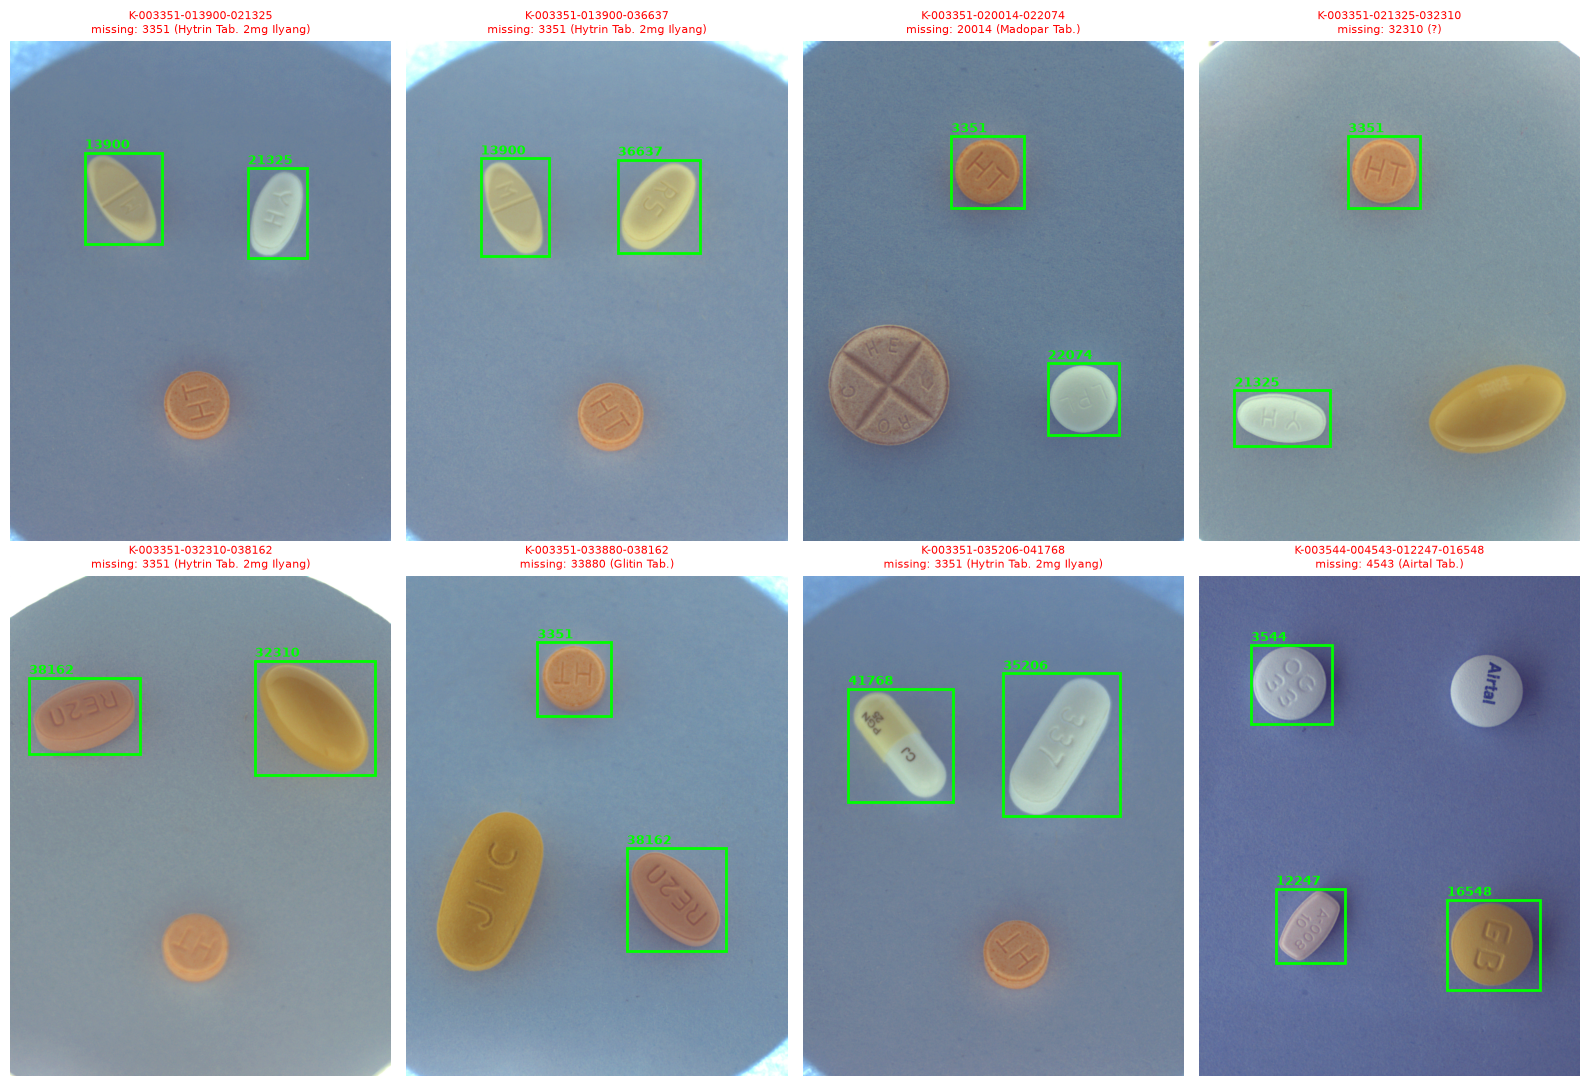

In [3]:
import math

import matplotlib.patches as patches
import matplotlib.pyplot as plt

# 한글 폰트 없이도 깨지지 않도록 영문 약 이름을 쓴다
name_en = dict(zip(cat_df["category_id"], cat_df["dl_name_en"]))


def draw_boxes(ax, file_name):
    """이미지에 라벨된 bbox를 초록색으로 그린다."""
    ax.imshow(plt.imread(TRAIN_IMG_DIR / file_name))
    for r in ann_df[ann_df["file_name"] == file_name].itertuples():
        ax.add_patch(patches.Rectangle((r.x, r.y), r.w, r.h, fill=False, edgecolor="lime", linewidth=2))
        ax.text(r.x, r.y - 10, str(r.category_id), color="lime", fontsize=9, weight="bold")
    ax.axis("off")


cols = 4
rows = math.ceil(len(missing_df) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 5.5), squeeze=False)
for ax, r in zip(axes.flat, missing_df.itertuples()):
    draw_boxes(ax, r.file_name)
    missing = "\n".join(f"{c} ({name_en.get(c) or '?'})" for c in r.missing_codes)
    ax.set_title(f"{r.file_name.split('_')[0]}\nmissing: {missing}", fontsize=8, color="red")
for ax in axes.flat[len(missing_df):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 데이터를 열어보니 하나의 이미지 안에 정답 박스가 전부 없는 것이 아니라, 하나의 알약에만 정답 박스가 없다.
### 이러한 데이터를 그대로 훈련에 사용되면 발생할 수 있는 문제
1. 빠진 알약을 배경으로 학습.
=> 결과적으로 약을 덜 검출하는 쪽으로, 모델이 미탐 쪽으로 기울 수 있다.
2. 같은 약에 대해 정답이 헷갈린다.
=> 3351(Hytrin)은 다른 사진에서는 "알약"으로 라벨돼 있는데, 이 4장에서는 "배경"으로 취급됩니다. 결과적으로 모델이 해당 약에 대한 확신이 낮아질 수 있다.
3. 이 이미지가 그대로 validation 세트에 들어가면, 모델이 빠진 알약을 맞게 찾아도 오답(false positive)으로 채점됨.
4. 데이터 증강이 문제를 퍼뜨릴 수 있다
박스 없는 알약 조각이 여러 학습 이미지에 섞여 들어가게 됨.

## 트레인 데이터에 알약들의 개수와 분포는 어떻게 될까?

In [4]:
# 알약(category_id)별 라벨된 bbox 수와 전체 대비 비율
class_counts = (
    ann_df["category_id"]
    .value_counts()
    .rename_axis("category_id")
    .reset_index(name="n_boxes")
    .merge(cat_df, on="category_id", how="left")
)
class_counts["ratio(%)"] = (class_counts["n_boxes"] / class_counts["n_boxes"].sum() * 100).round(2)

print("전체 bbox 수:", class_counts["n_boxes"].sum(), "/ 클래스 수:", len(class_counts))
class_counts[["category_id", "dl_name", "n_boxes", "ratio(%)"]]


전체 bbox 수: 763 / 클래스 수: 56


,category_id,dl_name,n_boxes,ratio(%)
0,3351,일양하이트린정 2mg,153,20.05
1,3483,기넥신에프정(은행엽엑스)(수출용),45,5.90
2,35206,아토젯정 10/40mg,37,4.85
3,16262,크레스토정 20mg,23,3.01
4,21325,아토르바정 10mg,22,2.88
5,16232,리피토정 20mg,21,2.75
6,3832,뉴로메드정(옥시라세탐),20,2.62
7,20238,플라빅스정 75mg,20,2.62
8,36637,로수젯정10/5밀리그램,19,2.49
9,16548,가바토파정 100mg,18,2.36


### 라벨 결측 약별 비율

| 빠진 약 (category_id) | 약 이름 | 라벨된 박스 | 빠진 박스 | 빠진 비율 |
|---|---|---:|---:|---:|
| 3351 | 일양하이트린정 2mg | 153 | 4 | 약 3% |
| 4543 | Airtal Tab. | 5 | 1 | 약 17% |
| 20014 | Madopar Tab. | 16 | 1 | 약 6% |
| 33880 | Glitin Tab. | 16 | 1 | 약 6% |
| 32310 | (영문명 없음) | 14 | 1 | 약 7% |

> 빠진 비율 = 빠진 박스 ÷ (라벨된 박스 + 빠진 박스)


## 결측치(bbox가 missing) 처리 방안
### 1. 그대로 쓰기
### 2. 빠진 박스 8개를 직접 그려 넣기
### 3. 전부 빼기(그렇게 된다면 멀쩡한 박스 16개도 손실)
### 4. 최소한 이 8장은 validation 세트에서 빼기

## 라벨 결측 보완

### 1. 원본 백업과 복원

- 원본 어노테이션 폴더를 `train_annotations_original`로 복사해 둔다. 이미 있으면 다시 복사하지 않는다.
- 이후 작업은 원본 json을 수정하지 않는다. 그래도 원본이 바뀌었다면 `restore_original()`로 백업에서 되돌린다.


In [5]:
import shutil

BACKUP_DIR = DATA_DIR / "train_annotations_original"
ADDED_PATH = DATA_DIR / "added_annotations.csv"  # 새로 추가한 박스만 따로 저장하는 파일

if not BACKUP_DIR.exists():
    shutil.copytree(ANN_DIR, BACKUP_DIR)
print("원본 json 수:", len(list(ANN_DIR.rglob("*.json"))), "/ 백업 json 수:", len(list(BACKUP_DIR.rglob("*.json"))))


def restore_original():
    """어노테이션 폴더를 백업 상태로 되돌리고, 추가 박스 파일을 지운다."""
    shutil.rmtree(ANN_DIR)
    shutil.copytree(BACKUP_DIR, ANN_DIR)
    ADDED_PATH.unlink(missing_ok=True)
    print("원본으로 복원 완료")


원본 json 수: 763 / 백업 json 수: 763
